In [2]:
!pip install xgboost lightgbm

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [4]:
data = {
    "Study_Hours": [2, 3, 5, 6, 8, 1, 4, 7, 9, 3, 6, 8, 2, 5, 7, 9, 4, 6, 8, 1],
    "Attendance": [60, 65, 80, 85, 95, 50, 70, 90, 98, 68,
                   88, 94, 55, 78, 91, 97, 72, 86, 93, 48],
    "Assignments": [3, 4, 7, 8, 10, 2, 5, 9, 10, 5,
                     8, 10, 3, 7, 9, 10, 6, 8, 9, 2],
    "Internal_Marks": [40, 45, 65, 75, 90, 30, 55, 82, 95, 48,
                       78, 88, 35, 62, 85, 94, 58, 76, 89, 28]
}

df = pd.DataFrame(data)

df["Pass"] = (
    (df["Study_Hours"] >= 4) &
    (df["Attendance"] >= 70) &
    (df["Internal_Marks"] >= 50)
).astype(int)

df

,Study_Hours,Attendance,Assignments,Internal_Marks,Pass
0,2,60,3,40,0
1,3,65,4,45,0
2,5,80,7,65,1
3,6,85,8,75,1
4,8,95,10,90,1
5,1,50,2,30,0
6,4,70,5,55,1
7,7,90,9,82,1
8,9,98,10,95,1
9,3,68,5,48,0


In [5]:
X = df.drop("Pass", axis=1)
y = df["Pass"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y)

Features:
Index(['Study_Hours', 'Attendance', 'Assignments', 'Internal_Marks'], dtype='object')

Target:
0     0
1     0
2     1
3     1
4     1
5     0
6     1
7     1
8     1
9     0
10    1
11    1
12    0
13    1
14    1
15    1
16    1
17    1
18    1
19    0
Name: Pass, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (15, 4)
Testing Data: (5, 4)


In [7]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42
)

bagging_model.fit(X_train, y_train)

bagging_pred = bagging_model.predict(X_test)

bagging_accuracy = accuracy_score(y_test, bagging_pred)

print("Bagging Accuracy:", bagging_accuracy)

Bagging Accuracy: 1.0


In [8]:
print(classification_report(y_test, bagging_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [9]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 1.0


In [10]:
adaboost = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

adaboost.fit(X_train, y_train)

ada_pred = adaboost.predict(X_test)

ada_accuracy = accuracy_score(y_test, ada_pred)

print("AdaBoost Accuracy:", ada_accuracy)

AdaBoost Accuracy: 0.8


In [11]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 1.0


In [12]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [13]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_test)

lgbm_accuracy = accuracy_score(y_test, lgbm_pred)

print("LightGBM Accuracy:", lgbm_accuracy)

LightGBM Accuracy: 0.6


In [14]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_test)

lgbm_accuracy = accuracy_score(y_test, lgbm_pred)

print("LightGBM Accuracy:", lgbm_accuracy)

LightGBM Accuracy: 0.6


In [15]:
print(classification_report(y_test, lgbm_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.60      1.00      0.75         3

    accuracy                           0.60         5
   macro avg       0.30      0.50      0.38         5
weighted avg       0.36      0.60      0.45         5



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [16]:
results = pd.DataFrame({
    "Model": [
        "Bagging",
        "Random Forest",
        "AdaBoost",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        bagging_accuracy,
        rf_accuracy,
        ada_accuracy,
        xgb_accuracy,
        lgbm_accuracy
    ]
})

results

,Model,Accuracy
0,Bagging,1.0
1,Random Forest,1.0
2,AdaBoost,0.8
3,XGBoost,1.0
4,LightGBM,0.6


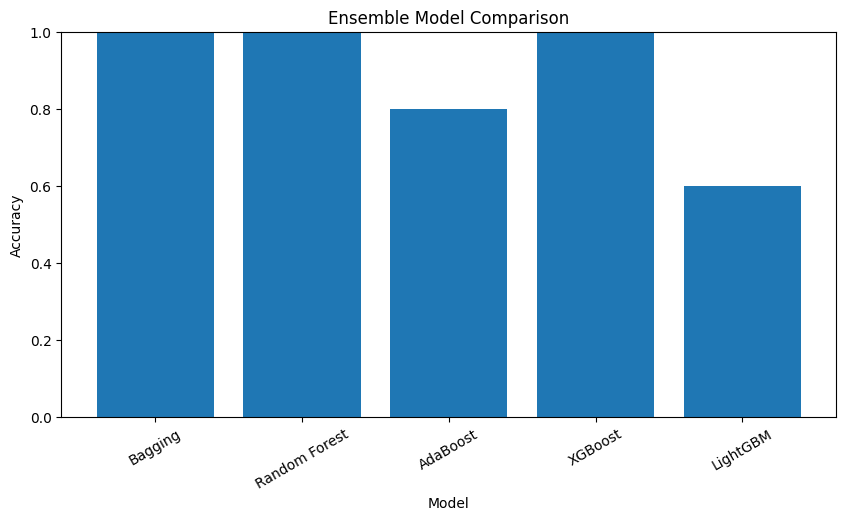

In [17]:
plt.figure(figsize=(10, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Ensemble Model Comparison")

plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.show()

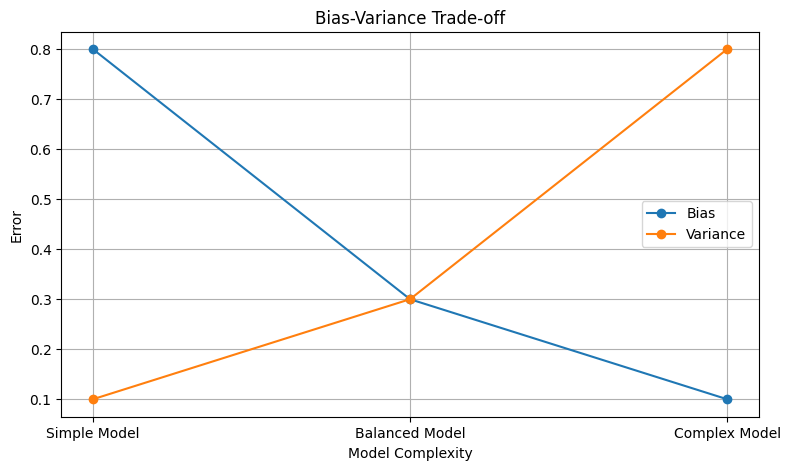

In [18]:
models = [
    "Simple Model",
    "Balanced Model",
    "Complex Model"
]

bias = [0.80, 0.30, 0.10]
variance = [0.10, 0.30, 0.80]

plt.figure(figsize=(9, 5))

plt.plot(models, bias, marker="o", label="Bias")
plt.plot(models, variance, marker="o", label="Variance")

plt.xlabel("Model Complexity")
plt.ylabel("Error")
plt.title("Bias-Variance Trade-off")

plt.legend()
plt.grid()

plt.show()

In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

l1_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=1.0,
    random_state=42
)

l1_model.fit(X_train_scaled, y_train)

l1_pred = l1_model.predict(X_test_scaled)

print("L1 Accuracy:", accuracy_score(y_test, l1_pred))

L1 Accuracy: 1.0


In [20]:
l2_model = LogisticRegression(
    penalty="l2",
    solver="liblinear",
    C=1.0,
    random_state=42
)

l2_model.fit(X_train_scaled, y_train)

l2_pred = l2_model.predict(X_test_scaled)

print("L2 Accuracy:", accuracy_score(y_test, l2_pred))

L2 Accuracy: 1.0


In [21]:
regularization_results = pd.DataFrame({
    "Method": ["L1 Regularization", "L2 Regularization"],
    "Accuracy": [
        accuracy_score(y_test, l1_pred),
        accuracy_score(y_test, l2_pred)
    ]
})

regularization_results

,Method,Accuracy
0,L1 Regularization,1.0
1,L2 Regularization,1.0


In [22]:
C_values = [0.01, 0.1, 1, 10, 100]

accuracies = []

for c in C_values:

    model = LogisticRegression(
        penalty="l2",
        C=c,
        solver="liblinear",
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, prediction)

    accuracies.append(accuracy)

regularization_df = pd.DataFrame({
    "C Value": C_values,
    "Accuracy": accuracies
})

regularization_df

,C Value,Accuracy
0,0.01,1.0
1,0.10,1.0
2,1.00,1.0
3,10.00,1.0
4,100.00,1.0


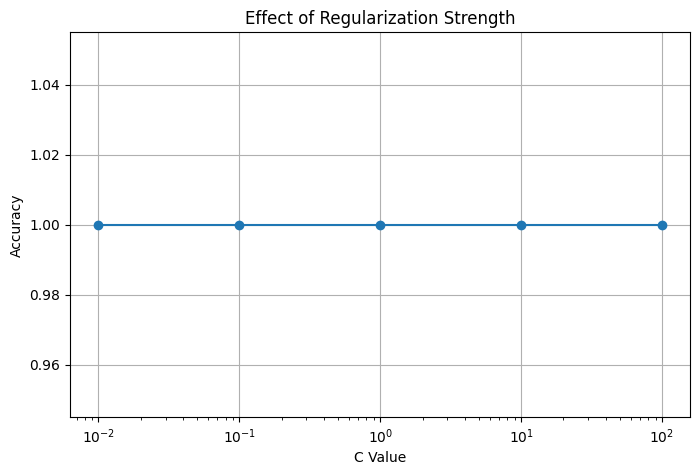

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    C_values,
    accuracies,
    marker="o"
)

plt.xscale("log")

plt.xlabel("C Value")
plt.ylabel("Accuracy")
plt.title("Effect of Regularization Strength")

plt.grid()

plt.show()